# Cancer Gene Expression Analysis: PCA and K-Means Clustering

Unsupervised Machine Learning | Dimensionality Reduction | TCGA RNA-Seq Data

This project is another application by which I aim to gain practical experience in the K-means clustering algorithm.

This collection of data is part of the RNA-Seq (HiSeq) PANCAN dataset, it is a random extraction of gene expressions of patients having different types of tumor: 

- **BRCA:** Breast carcinoma
- **KIRC:** Kidney renal clear-cell carcinoma
- **COAD:** Colon adenocarcinoma
- **LUAD:** Lung adenocarcinoma
- **PRAD:** Prostate cancer

The dataset contains 20,531 different gene expression variables (features) measured across 801 cancer samples.
Samples are RNA-Seq gene expression levels measured by illumina HiSeq platform.

The data is available in UCI Machine Learning Repository: 

https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq

# Project outline: 
- Data cleaning and validation
- Data standardization
- Dimensionality reduction using PCA (Principal Component Analysis)
- K-means clustering
- Metrics discussion
- Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("TCGA_Cancer_Complete.csv")

In [3]:
df.head(20)

,Unnamed: 0,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,...,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530,Class
0,sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,...,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.000000,PRAD
1,sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,...,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.000000,LUAD
2,sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,...,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.000000,PRAD
3,sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,...,8.792959,10.141520,8.942805,9.601208,11.392682,9.694814,9.684365,3.292001,0.000000,PRAD
4,sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,...,8.891425,10.373790,7.181162,9.846910,11.922439,9.217749,9.461191,5.110372,0.000000,BRCA
5,sample_5,0.0,3.467853,3.581918,6.620243,9.706829,0.0,7.758510,0.000000,0.0,...,8.602588,9.928339,6.096154,9.816001,11.556995,9.244150,9.836473,5.355133,0.000000,PRAD
6,sample_6,0.0,1.224966,1.691177,6.572007,9.640511,0.0,6.754888,0.531868,0.0,...,7.927968,9.673966,1.877744,9.802692,13.256060,9.664486,9.244219,8.330912,0.000000,KIRC
7,sample_7,0.0,2.854853,1.750478,7.226720,9.758691,0.0,5.952103,0.000000,0.0,...,8.277092,9.599230,5.244290,9.994339,12.670377,9.987733,9.216872,6.551490,0.000000,PRAD
8,sample_8,0.0,3.992125,2.772730,6.546692,10.488252,0.0,7.690222,0.352307,0.0,...,9.597533,9.763753,7.933278,10.952880,12.498919,10.389954,10.390255,7.828321,0.000000,BRCA
9,sample_9,0.0,3.642494,4.423558,6.849511,9.464466,0.0,7.947216,0.724214,0.0,...,8.712809,10.259096,6.131583,9.923582,11.144295,9.244851,9.484299,4.759151,0.000000,PRAD


In [4]:
df.shape

(801, 20533)

In [5]:
print("Cancer types:", df["Class"].unique())

Cancer types: <ArrowStringArray>
['PRAD', 'LUAD', 'BRCA', 'KIRC', 'COAD']
Length: 5, dtype: str


In [6]:
df.isna().sum().sum()

np.int64(0)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns.duplicated().sum()

np.int64(0)

In [9]:
gene_data = df.filter(regex=r"^gene_\d+$")

duplicate_gene_columns = gene_data.T.duplicated()

print("Duplicate gene columns:",
      duplicate_gene_columns.sum())

Duplicate gene columns: 266


In [10]:
duplicate_names = gene_data.columns[duplicate_gene_columns]
duplicate_df = df.loc[:, duplicate_names]
display(duplicate_df.head(10))

,gene_23,gene_4370,gene_4808,gene_4809,gene_4814,gene_4816,gene_4817,gene_4831,gene_5288,gene_7661,...,gene_18908,gene_18909,gene_18910,gene_18911,gene_18914,gene_18915,gene_19450,gene_19451,gene_19452,gene_19671
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**The dataset contains 266 columns with the same values.**

In [11]:
(duplicate_df == 0).all().all()

np.True_

In [12]:
constant_genes = gene_data.columns[gene_data.nunique() == 1]
print("Number of constant genes:", len(constant_genes))

Number of constant genes: 267


In [13]:
(gene_data[constant_genes] == 0).all().all()

np.True_

### Removing Columns with Zero Gene Expression
- 267 gene columns were identified with zero expression across all 801 samples.
- These columns provide no useful information for K-means clustering because they contain no variation between samples.
- These 267 columns will be removed.
- Remaining gene features: 20,533 − 267 = 20,266.

In [14]:
df_clean = df.drop(columns=constant_genes)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (801, 20533)
Cleaned dataset: (801, 20266)


In [15]:
df_clean.select_dtypes(exclude="number").columns.tolist()

['Unnamed: 0', 'Class']

In [16]:
# Select only the gene expression features
X = df_clean.filter(regex=r"^gene_\d+$")

# Check how many negative values exist
negative_count = (X < 0).sum().sum()
print("Number of negative values:", negative_count)

Number of negative values: 0


### Checking Data Types

We verified that all 20,264 gene expression features are numerical. Only two columns are non-numerical:
- **Unnamed**: 0: Sample identifiers
- **Class**: Cancer type labels
These two columns will be excluded from K-means clustering because the algorithm uses numerical features to calculate distances between samples.

# Cancer class distribution

In [17]:
# Number of samples per cancer type
class_counts = df_clean["Class"].value_counts()

print(class_counts)

Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


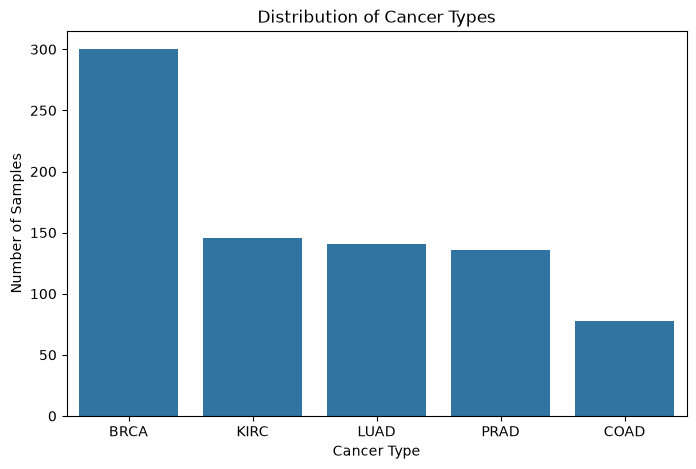

In [18]:
# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="Class", order=class_counts.index)

plt.title("Distribution of Cancer Types")
plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")
plt.show()

# Gene expression distributions (first five genes in the dataset)

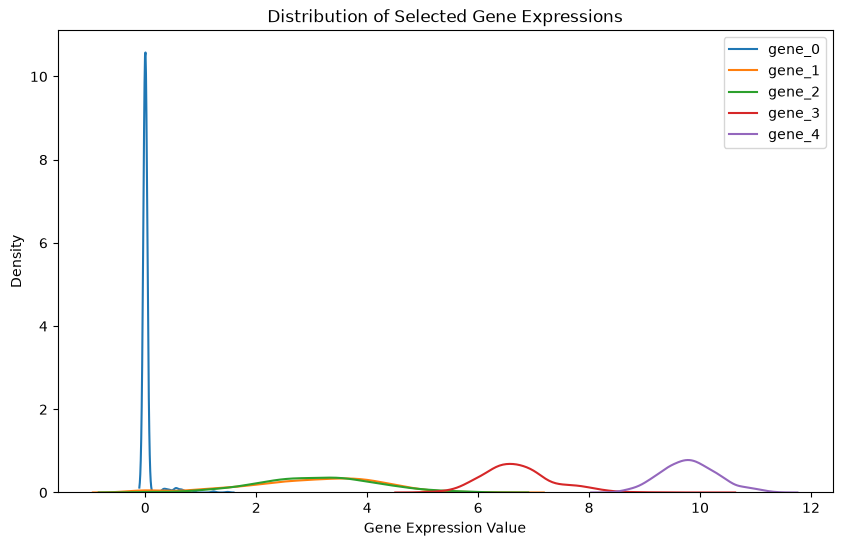

In [19]:
# Select the first 5 gene columns
selected_genes = X.columns[:5]

# Visualize gene expression distributions
plt.figure(figsize=(10, 6))

for gene in selected_genes:
    sns.kdeplot(X[gene], label=gene)

plt.title("Distribution of Selected Gene Expressions")
plt.xlabel("Gene Expression Value")
plt.ylabel("Density")
plt.legend()
plt.show()

**There are noticeable differences in both the typical expression levels and the spread of values across genes.**

In [20]:
# Summary statistics for selected genes
X[selected_genes].describe().T

,count,mean,std,min,25%,50%,75%,max
gene_0,801.0,0.026642,0.136850,0.000000,0.000000,0.000000,0.000000,1.482332
gene_1,801.0,3.010909,1.200828,0.000000,2.299039,3.143687,3.883484,6.237034
gene_2,801.0,3.095350,1.065601,0.000000,2.390365,3.127006,3.802534,6.063484
gene_3,801.0,6.722305,0.638819,5.009284,6.303346,6.655893,7.038447,10.129528
gene_4,801.0,9.813612,0.506537,8.435999,9.464466,9.791599,10.142324,11.355621


# Standardization using StandardScaler to make the features more comparable for K-Means.

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Standardize gene expression features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# Compare statistics before and after scaling
print("Before scaling:")
print(X.iloc[:, :5].agg(["mean", "std"]).T)

print("\nAfter scaling:")
print(X_scaled_df.iloc[:, :5].agg(["mean", "std"]).T)

Before scaling:
            mean       std
gene_0  0.026642  0.136850
gene_1  3.010909  1.200828
gene_2  3.095350  1.065601
gene_3  6.722305  0.638819
gene_4  9.813612  0.506537

After scaling:
                mean       std
gene_0 -7.761859e-18  1.000625
gene_1 -2.882976e-17  1.000625
gene_2  5.211534e-16  1.000625
gene_3  9.979533e-17  1.000625
gene_4 -1.729786e-16  1.000625


# StandardScaler :
It changes the mean and standard deviation. After standardization, the features have comparable variances, so large-variance genes no longer dominate simply because of their numerical spread.

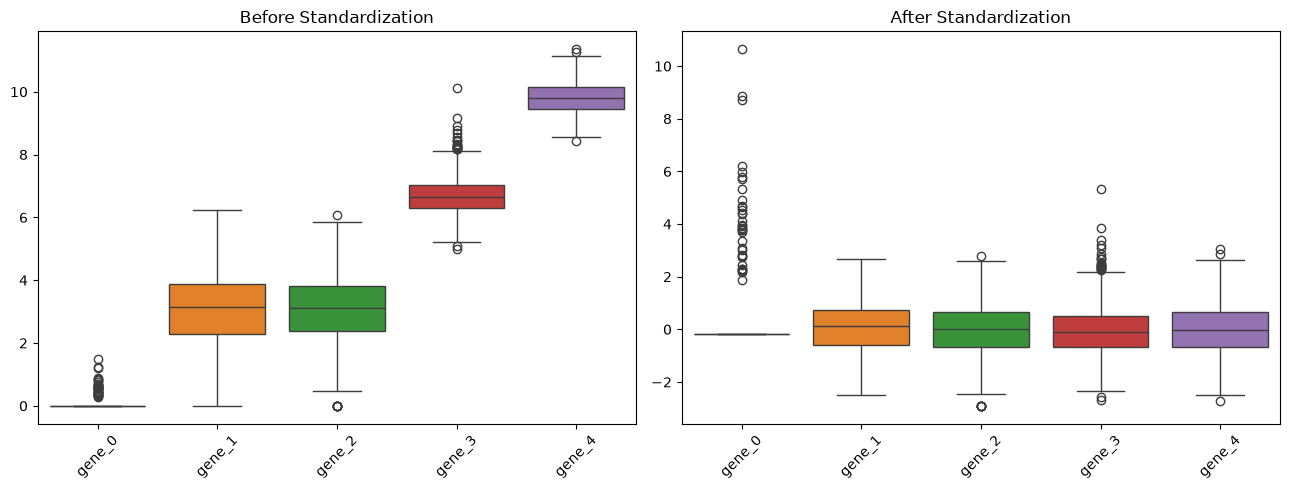

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Before scaling
sns.boxplot(data=X.iloc[:, :5], ax=axes[0])
axes[0].set_title("Before Standardization")
axes[0].tick_params(axis="x", rotation=45)

# After scaling
sns.boxplot(data=X_scaled_df.iloc[:, :5], ax=axes[1])
axes[1].set_title("After Standardization")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [23]:
print("Original dataset shape:", X.shape)
print("Standardized dataset shape:", X_scaled.shape)
print("Number of standardized genes:", X_scaled_df.shape[1])

# Verify scaling for ALL genes
print("Largest absolute mean:", X_scaled_df.mean().abs().max())

print("Minimum standard deviation:", X_scaled_df.std(ddof=0).min())

print("Maximum standard deviation:", X_scaled_df.std(ddof=0).max())

Original dataset shape: (801, 20264)
Standardized dataset shape: (801, 20264)
Number of standardized genes: 20264
Largest absolute mean: 7.826171393562402e-15
Minimum standard deviation: 0.9999999999999768
Maximum standard deviation: 1.0000000000000229


All 20,264 gene expression features were standardized using StandardScaler. The transformation preserved the dataset dimensions (801 × 20,264). Verification showed that all features have approximately zero mean and unit variance, confirming successful standardization.

# PCA (Principal Component Analysis)

### Comparing Different Numbers of Components

To investigate how the number of principal components affects the variance retained from the original gene-expression dataset, we will compare different PCA configurations.

**Number of PCA components**: 10, 20, 50, 75, 100, 150, and 200.

The cumulative explained variance will be used to compare these configurations. It represents the percentage of the original dataset's total variance preserved by the selected principal components.

In [25]:
from sklearn.decomposition import PCA

component_options = [10, 20, 50, 75, 100, 150, 200]

for n in component_options:
    pca = PCA(n_components=n, random_state=42)
    X_reduced = pca.fit_transform(X_scaled)

    variance = pca.explained_variance_ratio_.sum() * 100

    print(n, "components:", round(variance, 2), "%")

10 components: 46.59 %
20 components: 53.69 %
50 components: 63.67 %
75 components: 68.58 %
100 components: 72.0 %
150 components: 77.19 %
200 components: 81.04 %


#### The results show that PCA with fewer than 100 components retains a smaller proportion of the original dataset's variance.

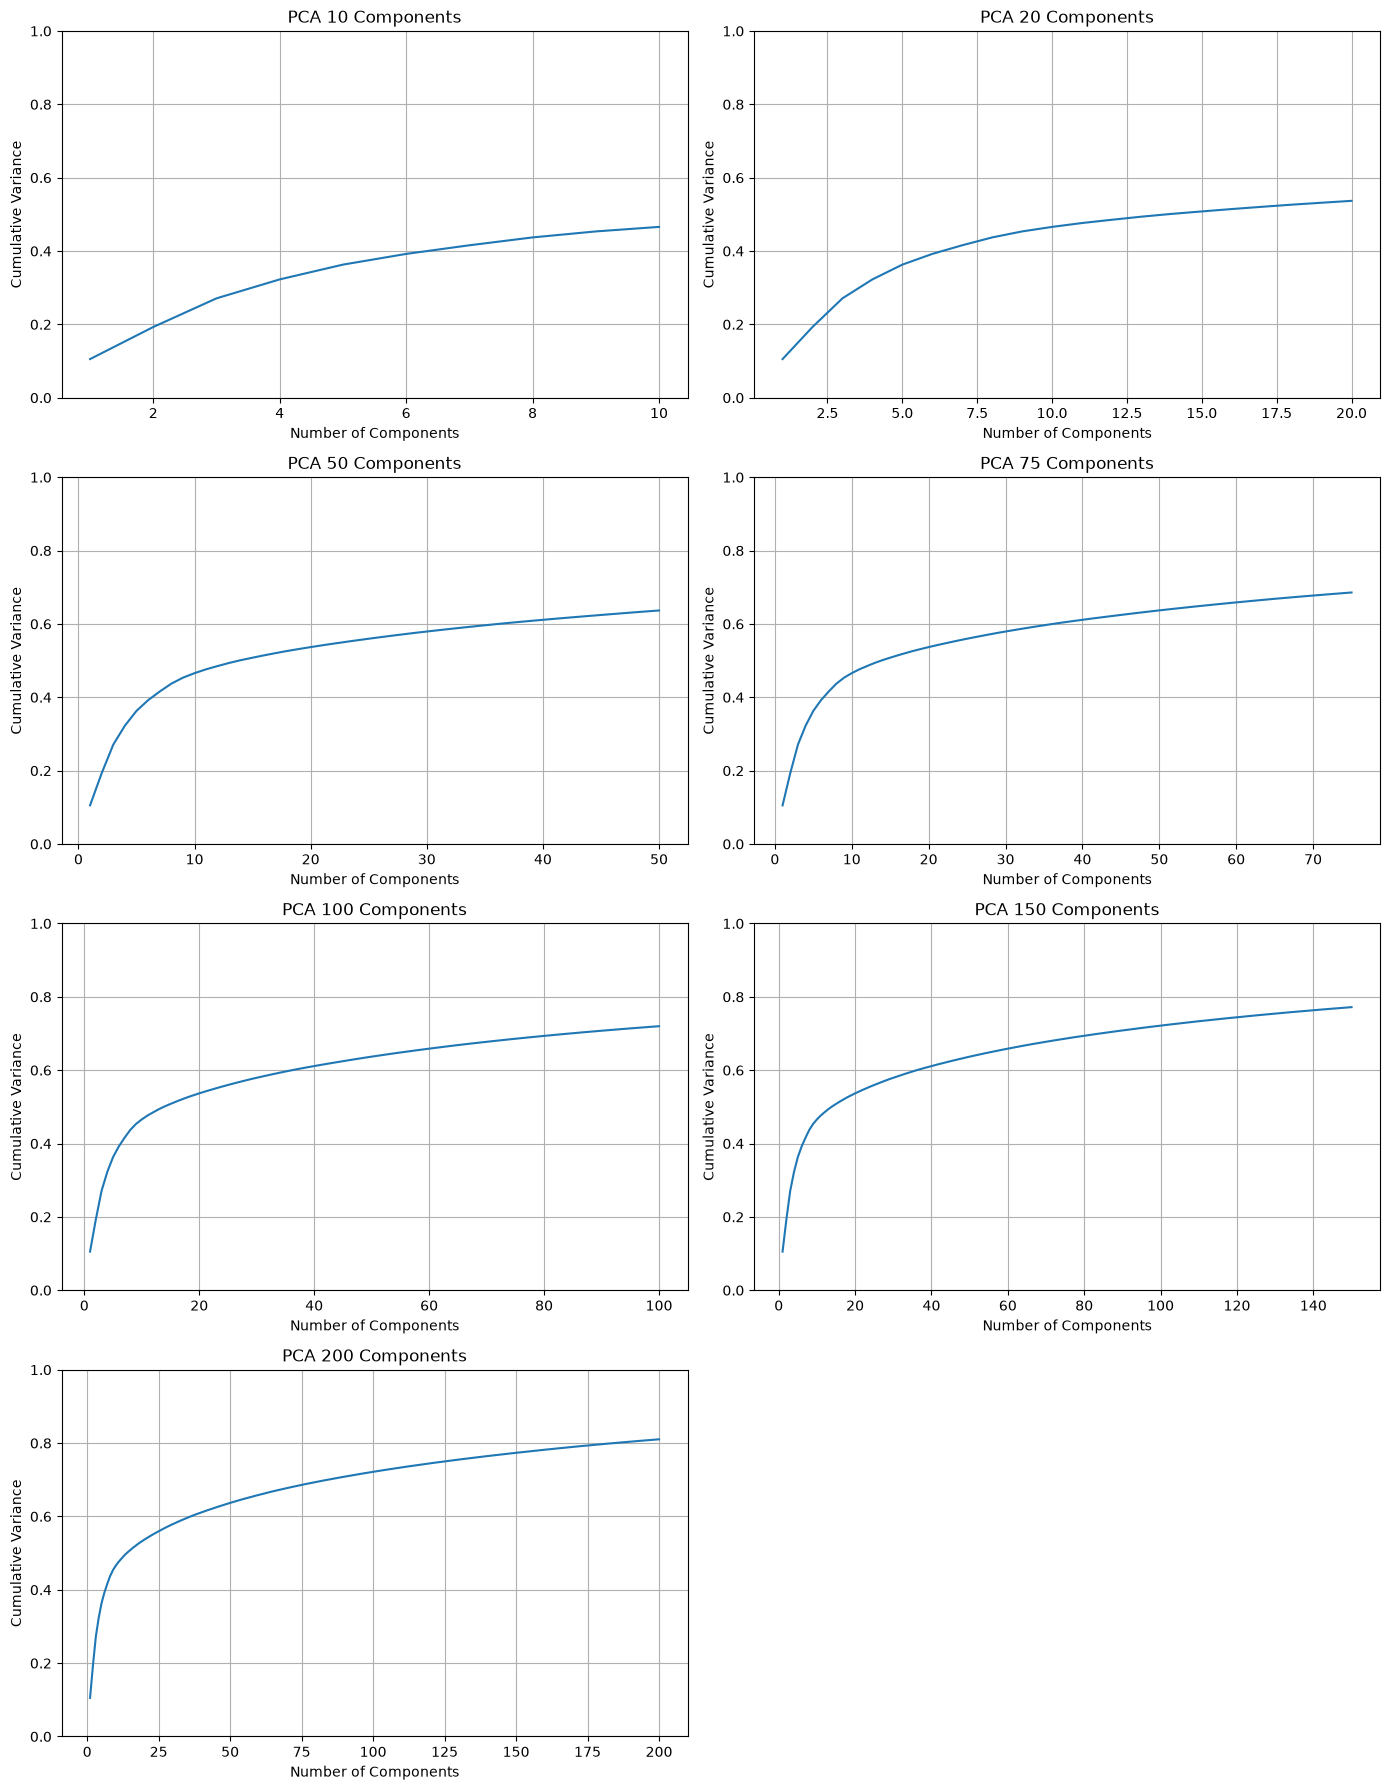

In [30]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for i, n in enumerate(component_options):
    pca = PCA(n_components=n, random_state=42)
    pca.fit(X_scaled)

    cumulative_variance = np.cumsum(
        pca.explained_variance_ratio_
    )

    axes.flat[i].plot(range(1, n + 1), cumulative_variance)
    axes.flat[i].set_title(f"PCA {n} Components")
    axes.flat[i].set_xlabel("Number of Components")
    axes.flat[i].set_ylabel("Cumulative Variance")
    axes.flat[i].set_ylim(0, 1)
    axes.flat[i].grid(True)

# Hide the unused 8th subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

### PCA with 90% and 95% Explained Variance

To investigate how many principal components are required to preserve 90% and 95% of the dataset's total variance.

In [31]:
# PCA retaining 90% variance
pca_90 = PCA(n_components=0.90, svd_solver="full")
X_pca_90 = pca_90.fit_transform(X_scaled)

# PCA retaining 95% variance
pca_95 = PCA(n_components=0.95, svd_solver="full")
X_pca_95 = pca_95.fit_transform(X_scaled)

# Display results
for target, pca in [(90, pca_90), (95, pca_95)]:
    print(f"PCA {target}%")
    print("Number of components:", pca.n_components_)
    print("Explained variance:",
          round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
    print()

PCA 90%
Number of components: 373
Explained variance: 90.03 %

PCA 95%
Number of components: 530
Explained variance: 95.01 %



### The results show that:

- **PCA 90%**: 373 principal components are required to retain 90.03% of the total variance.
- **PCA 95%**: 530 principal components are required to retain 95.01% of the total variance.

# K-Means clustering
For this project, we know there are five cancer classes:
**BRCA, KIRC, LUAD, PRAD, and COAD**.
Let's start the experiment with **K = 5**.

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

component_options = [10, 20, 50, 75, 100, 150, 200]
results = []

# 1. K-Means for fixed PCA components
for n in component_options:
    pca = PCA(n_components=n, random_state=42)
    X_reduced = pca.fit_transform(X_scaled)

    model = KMeans(n_clusters=5, random_state=42, n_init=10)
    clusters = model.fit_predict(X_reduced)

    results.append({
        "PCA": f"{n} components",
        "Components": n,
        "Cumulative Variance (%)": pca.explained_variance_ratio_.sum() * 100,
        "Silhouette": silhouette_score(X_reduced, clusters),
        "ARI": adjusted_rand_score(df_clean["Class"], clusters)
    })

# 2. K-Means for PCA 90% and 95%
for name, X_reduced, pca in [
    ("90% variance", X_pca_90, pca_90),
    ("95% variance", X_pca_95, pca_95)
]:
    model = KMeans(n_clusters=5, random_state=42, n_init=10)
    clusters = model.fit_predict(X_reduced)

    results.append({
        "PCA": name,
        "Components": pca.n_components_,
        "Cumulative Variance (%)": pca.explained_variance_ratio_.sum() * 100,
        "Silhouette": silhouette_score(X_reduced, clusters),
        "ARI": adjusted_rand_score(df_clean["Class"], clusters)
    })

# 3. Display comparison table
kmeans_results = pd.DataFrame(results)

display(kmeans_results.round(2))

,PCA,Components,Cumulative Variance (%),Silhouette,ARI
0,10 components,10,46.59,0.33,0.79
1,20 components,20,53.69,0.28,0.81
2,50 components,50,63.67,0.23,0.82
3,75 components,75,68.58,0.22,0.80
4,100 components,100,72.00,0.20,0.80
5,150 components,150,77.19,0.19,0.80
6,200 components,200,81.04,0.18,0.80
7,90% variance,373,90.03,0.16,0.80
8,95% variance,530,95.01,0.15,0.80


# Evaluation with Silhouette Score
Before comparing the clusters to the known cancer classes, let's measure how well separated they are.
The Silhouette Score measures two things:

1. How similar a sample is to other samples in its own cluster.
2. How different that sample is from samples in neighboring clusters.

The score ranges from -1 to +1.
Score	Interpretation
- **Near +1**	Well-separated clusters
- **Near 0**	Overlapping or weakly separated clusters
- **Below 0**	Sample has been assigned to the wrong cluster

## Adjusted Rand Index (ARI):
To evaluate the agreement between K-Means clusters and the actual cancer classes (the five cancer types).

**Score Range and Interpretation:**

The score ranges from -1 to +1:
- **+1**: Perfect match between the predicted clusters and the actual labels.
- **Near 0**: Less agreement than expected.
- **Negative value**: The clustering agreement is even worse than what is expected.

PCA with 10 components gives the best cluster separation (0.33) among the tested configurations.

This suggests that additional components may introduce variation that makes the clusters appear less compact or less separated under the distance metric used by K-Means.

However, 0.33 still indicates that the clusters are not perfectly separated.
Adjusted Rand Index (ARI) remains relatively stable (0.79 to 0.82)

PCA with 50 components achieves the highest ARI (0.82), while PCA with 10 components achieves the highest Silhouette Score.

## K-Means Cluster and Centroid Visualization

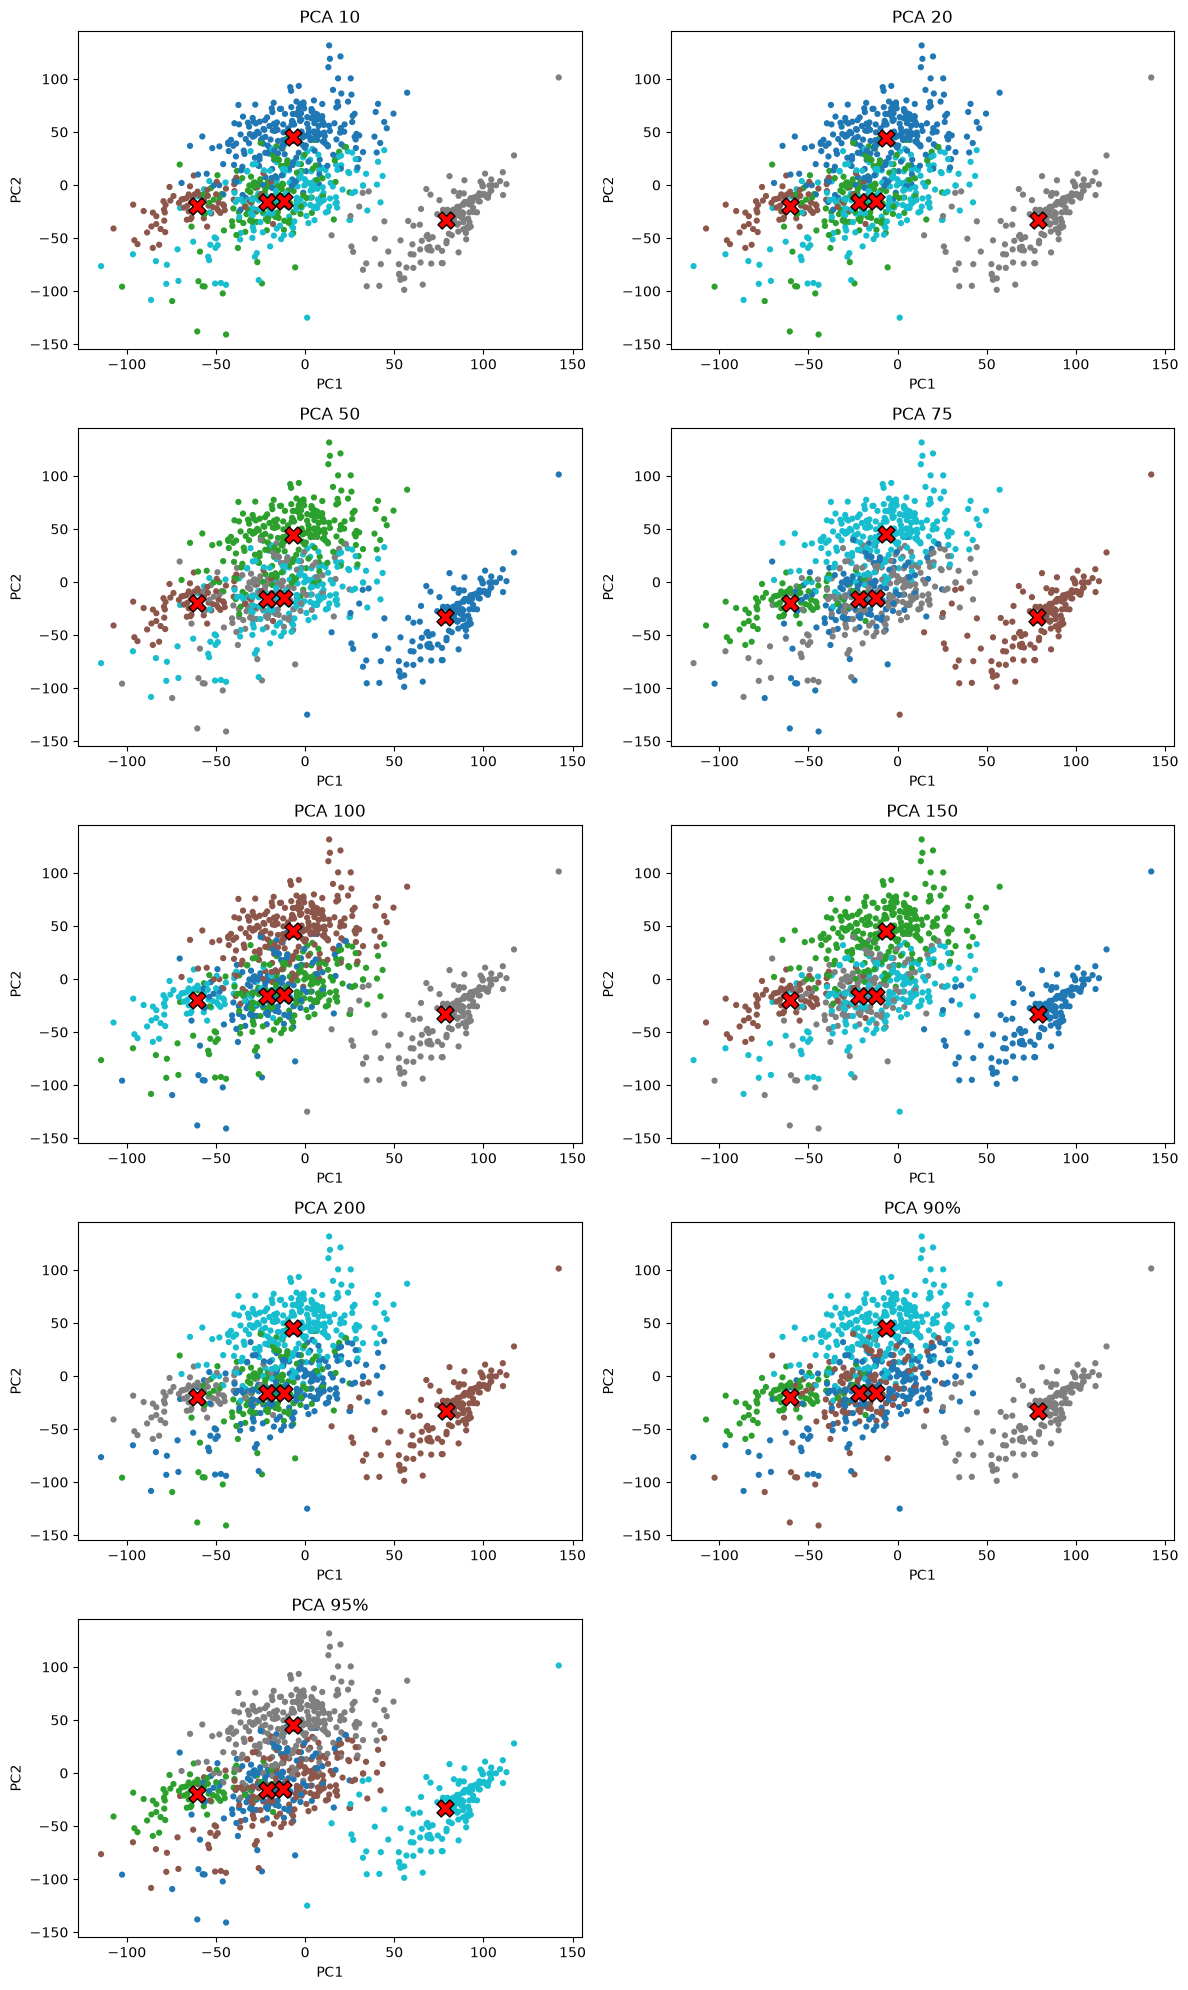

In [35]:
pca_data = {f"PCA {n}": PCA(n_components=n, random_state=42).fit_transform(X_scaled)
    for n in component_options
}

pca_data["PCA 90%"] = X_pca_90
pca_data["PCA 95%"] = X_pca_95

fig, axes = plt.subplots(5, 2, figsize=(12, 20))

for ax, (name, X) in zip(axes.flat, pca_data.items()):
    model = KMeans(n_clusters=5, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=12)
    ax.scatter(*model.cluster_centers_[:, :2].T,
               c="red", marker="X", s=150, edgecolors="black")

    ax.set(title=name, xlabel="PC1", ylabel="PC2")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation of K-Means Clustering Results
The results show that increasing the number of PCA components leads to higher cumulative explained variance but lower Silhouette Scores.

PCA with 10 components achieves the highest Silhouette Score (0.33), while retaining 46.59% of the original dataset's variance.

In contrast, PCA with 50 components achieves the highest Adjusted Rand Index (0.82), indicating the strongest agreement with the known cancer types.

For configurations retaining 90% and 95% explained variance, the Silhouette Scores decrease to 0.16 and 0.15, respectively, while ARI remains approximately 0.80.

These findings suggest that retaining more variance does not necessarily improve clustering performance. Some additional components may capture variation that does not contribute to cancer-type separation.

**PCA with 10 components is provisionally selected** because it provides the strongest cluster separation, relatively high agreement with the known cancer types, and substantially reduced dimensionality.

# Cancer Types vs. K-Means Clusters

To evaluate how well the five clusters correspond to the known cancer types, a heatmap will be created.
The heatmap shows the number of samples from each cancer type assigned to each cluster, helping identify correctly grouped cancer types and mixed clusters.

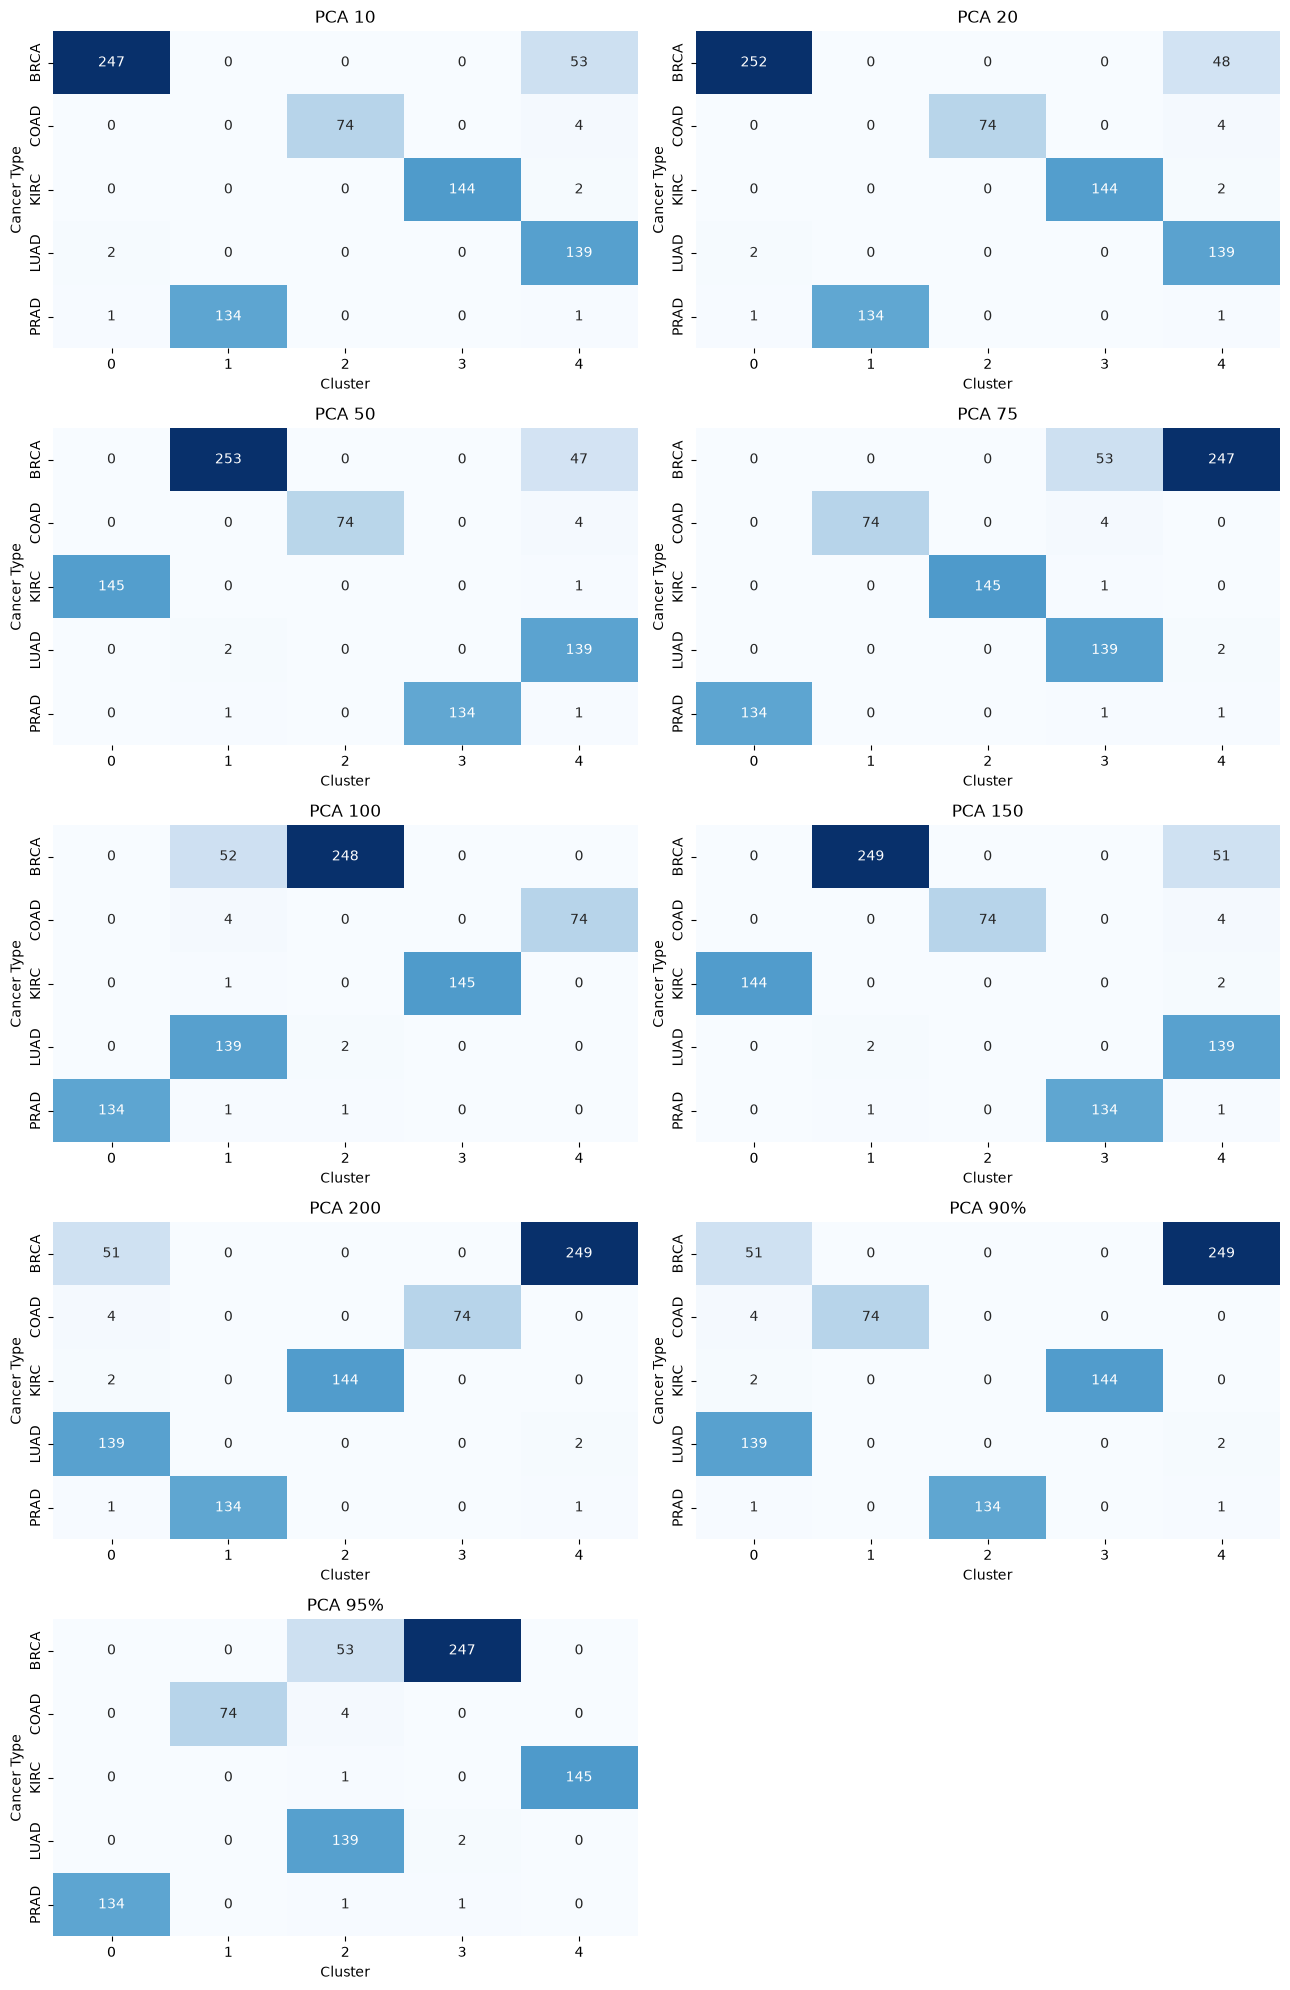

In [36]:
fig, axes = plt.subplots(5, 2, figsize=(13, 20))

for ax, (name, X) in zip(axes.flat, pca_data.items()):
    model = KMeans(n_clusters=5, random_state=42, n_init=10)
    clusters = model.fit_predict(X)

    comparison = pd.crosstab(
        df_clean["Class"].to_numpy(),
        clusters
    )

    sns.heatmap(comparison, annot=True, fmt="d",
                cmap="Blues", ax=ax, cbar=False)

    ax.set_title(name)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Cancer Type")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


The heatmaps show that K-Means produces similar clustering patterns across the nine PCA configurations.
Most PRAD, KIRC, COAD, and LUAD samples are consistently concentrated in separate clusters, indicating strong agreement between the discovered groups and the known cancer types.

# Conclusion:
Increasing the number of principal components does not substantially improve the separation of cancer types.
Overall, PCA with 10 components provides a simpler representation while maintaining clustering patterns similar to those obtained with higher-dimensional configurations.
The main finding is that preserving more variance does not necessarily produce better cancer-type clustering.